# ALERTASP | Previsão municipal de registros a partir da chuva
**FIAP — Global Solution 2026.2 | CitizenTech | Inteligência Artificial & Machine Learning**

**Equipe:** Enzo Almeida (RM556900) · Guilherme Moreira (RM557290) · Gabriel De Mello (RM554421)

**Pergunta:** *Com base na precipitação medida na estação A701 (São Paulo–Mirante) até o começo de um dia, qual é a probabilidade estimada de haver ao menos um registro de alagamento ou inundação em algum ponto do município de São Paulo nas próximas 24 horas?*

- **Unidade de análise:** município de São Paulo × dia civil local.
- **Alvo:** `1` se há pelo menos um registro das duas categorias na data (GeoSampa/SIGRC), `0` se **não consta registro**. Zero **não comprova** ausência de alagamento.
- **Horizonte:** 00:00 a 23:59 do dia-alvo, horário `America/Sao_Paulo`.
- **Informações disponíveis no início do dia:** chuva observada nos dias anteriores, época do ano.
- **Limite espacial:** uma estação não autoriza estimativas para bairro, rua ou rota. Não é um serviço operacional de alerta ou monitoramento em tempo real.
- **Fontes oficiais:** [GeoSampa Alagamento](https://metadados.geosampa.prefeitura.sp.gov.br/geonetwork/srv/api/records/432c06b1-03a1-4b1f-9210-423e1b58e869), [GeoSampa Inundação](https://metadados.geosampa.prefeitura.sp.gov.br/geonetwork/srv/api/records/9d08d20d-f6c7-463d-a349-c28c47babff2), [INMET Dados Históricos](https://portal.inmet.gov.br/dadoshistoricos).

**Condição de execução:** o CSV A701 de **2013** foi realmente inspecionado. Para treinar o experimento completo, devem existir também CSVs A701 de **2014–2025**. O de **2026** habilita a avaliação complementar parcial. O notebook verificará essa condição e **não gerará métricas inventadas**.

## 1. Critérios oficiais e desenho experimental

Rubrica do PDF FIAP (p. 31–33): dados públicos reais (2), modelo permitido justificado (1), limpeza e divisão treino/teste (2), ≥10 combinações de 3 hiperparâmetros e CV **somente no treino** (2), métricas e gráficos de treino/teste com discussão de overfitting (2), conclusão para cidadão (1). Entrega: `ml/` com notebook **executado**, `dados/README.md`, `requirements.txt`, `RELATORIO_ML.md`, vídeo até 5 min **não listado**, links no Teams até **19/11/2026 23h55**. **Divergência do PDF:** p. 31 fala 2–4 páginas e p. 33 fala 2 páginas; preparar 2 páginas e confirmar no Teams.

**Protocolo congelado antes da avaliação:** desenvolvimento + GridSearch 2013–2022; calibração probabilística 2023; diagnóstico de verificação 2024; avaliação retrospectiva 2025; 2026 é parcial e suplementar. Nenhum resultado de 2024–2026 é usado para escolher hiperparâmetros. O rótulo administrativo depende da cobertura e notificação, inclusive por equipes de campo; não é verdade de terreno exaustiva.

In [24]:
%pip -q install "pandas>=2.1,<3" "numpy>=1.24,<3" "scikit-learn>=1.4,<2" "matplotlib>=3.7,<4" "joblib>=1.3,<2"

In [25]:
import os, re, sys, json, hashlib, sqlite3, zipfile, tempfile, unicodedata
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, ParameterGrid
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    precision_score, recall_score, average_precision_score, roc_auc_score,
    brier_score_loss, confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve)
from sklearn.calibration import calibration_curve

SEED = 42
TZ = "America/Sao_Paulo"
# No Colab, usa o Drive. Fora do Colab, um diretório pode ser indicado pela variável de ambiente ALERTASP_BASE_DIR.
if "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/ALERTASP_ML_PREVISAO_ENTREGA_COMPLETA/ml")
else:
    BASE = Path(os.environ.get("ALERTASP_BASE_DIR", "/mnt/data/ALERTASP_ML_PREVISAO_ENTREGA_COMPLETA/ml"))

BRUTOS = BASE / "dados" / "brutos"
INMET = BRUTOS / "inmet" / "A701_MIRANTE"
PROCESSADOS = BASE / "dados" / "processados" / "chuva_a701"
FIGURAS = BASE / "figuras" / "chuva_a701"
EVIDENCIAS = BASE / "evidencias" / "chuva_a701"
for pasta in [PROCESSADOS, FIGURAS, EVIDENCIAS]:
    pasta.mkdir(parents=True, exist_ok=True)

print("Diretório:", BASE)
print("Estação INMET esperada:", INMET)
print("Scikit-learn:", sklearn.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Diretório: /content/drive/MyDrive/ALERTASP_ML_PREVISAO_ENTREGA_COMPLETA/ml
Estação INMET esperada: /content/drive/MyDrive/ALERTASP_ML_PREVISAO_ENTREGA_COMPLETA/ml/dados/brutos/inmet/A701_MIRANTE
Scikit-learn: 1.6.1


## 2. Verificar os arquivos necessários
Coloque os **CSV originais** da estação **A701** em `ml/dados/brutos/inmet/A701_MIRANTE/`, um ou mais arquivos por ano, de 2013 a 2026. O código reconhece pelo código da estação e pelo cabeçalho; não misture A755 ou estações de outras cidades nesta pasta. Mantenha o ZIP do GeoSampa em `ml/dados/brutos/` (ou uma subpasta). O histórico de 2026 já está dentro do ZIP do GeoSampa; não concatene os GeoJSONs separadamente.

In [26]:
zip_geosampa = list(BRUTOS.rglob("SIRGAS_GPKG_riscoocorrencia.zip"))
if len(zip_geosampa) != 1:
    raise FileNotFoundError("Coloque exatamente um SIRGAS_GPKG_riscoocorrencia.zip em dados/brutos/")
ZIP_GEO = zip_geosampa[0]

csvs_a701 = sorted(p for p in INMET.rglob("*") if p.is_file() and p.suffix.lower()==".csv"
                   and re.search(r"(?:^|_)A701(?:_|$)", p.name.upper())) if INMET.exists() else []
print("GeoSampa:", ZIP_GEO.name, round(ZIP_GEO.stat().st_size/1024**2, 2), "MB")
print("INMET A701 — arquivos encontrados:", len(csvs_a701))
for p in csvs_a701:
    print("  ", p.name)
if not csvs_a701:
    print("FALTA: coloque o arquivo de 2013 e os demais anos em", INMET)

GeoSampa: SIRGAS_GPKG_riscoocorrencia.zip 10.82 MB
INMET A701 — arquivos encontrados: 14
   INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2013_A_31-12-2013.CSV
   INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2014_A_31-12-2014.CSV
   INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2015_A_31-12-2015.CSV
   INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2016_A_31-12-2016.CSV
   INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2017_A_31-12-2017.CSV
   INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2018_A_31-12-2018.CSV
   INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2019_A_31-12-2019.CSV
   INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2020_A_31-12-2020.CSV
   INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2021_A_31-12-2021.CSV
   INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2022_A_31-12-2022.CSV
   INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2023_A_31-12-2023.CSV
   INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2024_A_31-12-2024.CSV
   INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2025_A_31-12-2025.CSV
   INMET_SE_SP_A701_SAO PAU

## 3. Leitura oficial do INMET — formatos pré e pós-2019
CSV: 8 linhas de metadados, `;`, Latin-1/CP1252, precipitação horária em mm e horário UTC. Até 2018 faltantes podem ser `-9999`, depois podem vir vazios. **Nenhum ausente é transformado em 0.** Horas UTC são convertidas para `America/Sao_Paulo`, respeitando mudanças históricas de horário de verão. Metadados e coordenadas são auditados por arquivo.

In [27]:
def sem_acentos(s):
    return "".join(c for c in unicodedata.normalize("NFKD", str(s))
                   if not unicodedata.combining(c)).upper().strip()

def ler_inmet_a701(caminho):
    with caminho.open("r", encoding="latin1", errors="replace") as f:
        linhas = [next(f).rstrip("\r\n") for _ in range(8)]
    meta = {}
    for linha in linhas:
        partes = linha.split(";", 1)
        if len(partes) == 2:
            meta[sem_acentos(partes[0]).rstrip(":")] = partes[1].strip()
    codigo = meta.get("CODIGO (WMO)", "").upper()
    if codigo != "A701":
        raise ValueError(f"{caminho.name}: código WMO {codigo!r}, esperava A701")

    tabela = pd.read_csv(caminho, sep=";", skiprows=8, encoding="latin1", dtype=str, low_memory=False)
    def achar(pred, nome):
        achadas = [c for c in tabela.columns if pred(sem_acentos(c))]
        if len(achadas) != 1:
            raise ValueError(f"{caminho.name}: coluna {nome} ambígua/ausente: {achadas}")
        return achadas[0]
    cd = achar(lambda s:s.startswith("DATA"), "data")
    ch = achar(lambda s:"HORA" in s and "UTC" in s, "hora UTC")
    cp = achar(lambda s:"PRECIPITACAO TOTAL" in s and "HOR" in s, "precipitação")

    d = tabela[cd].astype("string").str.strip().str.replace("/", "-", regex=False).str[:10]
    h = tabela[ch].astype("string").str.extract(r"(\d{1,2}):?(\d{2})")
    hh = h[0].str.zfill(2) + ":" + h[1]
    instantes = pd.to_datetime(d + " " + hh, errors="coerce", utc=True)
    chuva = pd.to_numeric(tabela[cp].astype("string").str.strip().str.replace(",", ".", regex=False), errors="coerce")
    chuva = chuva.mask(chuva < 0)  # -9999 = sem medida, nunca 0
    if (chuva > 500).any():
        raise ValueError(f"{caminho.name}: precipitação horária >500 mm; verificar fonte")
    if instantes.isna().any():
        raise ValueError(f"{caminho.name}: {instantes.isna().sum()} timestamps UTC inválidos")
    anos = sorted(instantes.dt.year.unique().tolist())
    if len(anos) != 1:
        raise ValueError(f"{caminho.name}: contém mais de um ano UTC: {anos}")
    out = pd.DataFrame({"utc": instantes, "chuva_mm": chuva.astype(float)})
    resumo = {
        "ano_utc": anos[0], "arquivo": caminho.name, "linhas": len(out),
        "horas_validas": int(chuva.notna().sum()),
        "horas_sem_precipitacao": int(chuva.isna().sum()),
        "latitude": meta.get("LATITUDE", ""),
        "longitude": meta.get("LONGITUDE", ""),
        "nome_estacao": meta.get("ESTACAO", ""),
    }
    return out, resumo

partes, inventario = [], []
for arq in csvs_a701:
    df, info = ler_inmet_a701(arq)
    partes.append(df)
    inventario.append(info)

inv = pd.DataFrame(inventario)
if not inv.empty:
    display(inv.sort_values("ano_utc"))
    inv.to_csv(EVIDENCIAS/"inventario_inmet_a701.csv", index=False)
    # Arquivos parciais/duplicados por ano exigem revisão manual para não inflar horas.
    repetidos = inv.loc[inv.duplicated("ano_utc", keep=False)]
    if not repetidos.empty:
        raise ValueError("Mais de um arquivo por ano para A701. Revise os recortes antes de prosseguir.")
    horas = pd.concat(partes, ignore_index=True).sort_values("utc")
    if horas["utc"].duplicated().any():
        raise ValueError("Timestamps UTC repetidos entre arquivos INMET")
else:
    horas = pd.DataFrame({"utc":pd.Series(dtype="datetime64[ns, UTC]"),
                          "chuva_mm":pd.Series(dtype="float64")})

ANOS_NECESSARIOS = set(range(2013, 2026))
anos_encontrados = set(inv["ano_utc"].astype(int)) if not inv.empty else set()
ANOS_FALTANTES = sorted(ANOS_NECESSARIOS - anos_encontrados)
print("Anos faltantes para treinar/avaliar até 2025:", ANOS_FALTANTES)
print("Arquivo de 2026 presente?", 2026 in anos_encontrados)

,ano_utc,arquivo,linhas,horas_validas,horas_sem_precipitacao,latitude,longitude,nome_estacao
0,2013,INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-201...,8760,8714,46,"-23,48333333","-46,61666666",SAO PAULO - MIRANTE
1,2014,INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-201...,8760,8556,204,"-23,48333333","-46,61666666",SAO PAULO - MIRANTE
2,2015,INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-201...,8760,8760,0,"-23,48333333","-46,61666666",SAO PAULO - MIRANTE
3,2016,INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-201...,8784,8718,66,"-23,48333333","-46,61666666",SAO PAULO - MIRANTE
4,2017,INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-201...,8760,8687,73,"-23,48333333","-46,61666666",SAO PAULO - MIRANTE
5,2018,INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-201...,8760,8757,3,"-23,48333333","-46,61666666",SAO PAULO - MIRANTE
6,2019,INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-201...,8760,8760,0,"-23,496294","-46,620088",
7,2020,INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-202...,8784,8782,2,"-23,496294","-46,620088",SAO PAULO - MIRANTE
8,2021,INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-202...,8760,8759,1,"-23,496294","-46,620088",SAO PAULO - MIRANTE
9,2022,INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-202...,8760,8759,1,"-23,49638888","-46,61999999",SAO PAULO - MIRANTE


Anos faltantes para treinar/avaliar até 2025: []
Arquivo de 2026 presente? True


## 4. Verificação da base GeoSampa — sem somar registros duplicados
Lemos somente `data` e `ocorrencia`, as duas categorias de interesse. A contagem é por **dia com ≥1 registro**, e não pelo número de notificações do mesmo episódio. Não presumimos que dia sem registro signifique ausência física de alagamento.

In [28]:
def carregar_registros_gpkg(arquivo_zip):
    registros = []
    with tempfile.TemporaryDirectory() as temporaria, zipfile.ZipFile(arquivo_zip) as z:
        todos = z.namelist()
        for ano in range(2013, 2027):
            encontrados = [nome for nome in todos if nome.endswith(f"riscoocorrencia_{ano}.gpkg")]
            if len(encontrados) != 1:
                raise ValueError(f"GeoSampa: esperava exatamente 1 GPKG em {ano}; encontrado: {encontrados}")
            destino = Path(temporaria) / f"dados_{ano}.gpkg"
            destino.write_bytes(z.read(encontrados[0]))
            with sqlite3.connect(destino) as con:
                tabs = con.execute("SELECT table_name FROM gpkg_contents WHERE data_type='features'").fetchall()
                if len(tabs) != 1:
                    raise ValueError(f"Ano {ano}: {len(tabs)} camadas vetoriais")
                tab = tabs[0][0]
                if '"' in tab:
                    raise ValueError("Nome inválido de camada")
                consulta = "SELECT data, ocorrencia FROM " + tab + " WHERE ocorrencia IN ('ALAGAMENTO','INUNDACAO')"
                df = pd.read_sql_query(consulta, con)
            dia = pd.to_datetime(df["data"].astype(str).str[:10].str.replace("/", "-", regex=False), errors="coerce")
            if dia.isna().any():
                raise ValueError(f"GeoSampa {ano}: datas inválidas")
            df["dia"] = dia.dt.normalize()
            df["ano_arquivo"] = ano
            registros.append(df[["dia", "ocorrencia", "ano_arquivo"]])
    return pd.concat(registros, ignore_index=True)

geo = carregar_registros_gpkg(ZIP_GEO)
print("Registros das duas categorias:", len(geo))
print("Dias distintos com registro até 2025:", geo.loc[geo.ano_arquivo<=2025, "dia"].nunique())
assert len(geo)==12625, "Arquivo GeoSampa diferente do auditado; revise a versão da fonte"
resumo_geo = geo.groupby(["ano_arquivo", "ocorrencia"]).size().unstack(fill_value=0)
display(resumo_geo)
resumo_geo.to_csv(EVIDENCIAS/"contagens_geosampa_por_ano.csv")

dias_reg = geo.groupby(["dia", "ocorrencia"]).size().unstack(fill_value=0)
for nome in ["ALAGAMENTO", "INUNDACAO"]:
    if nome not in dias_reg: dias_reg[nome] = 0
ultimo_reg_2026 = geo.loc[geo.ano_arquivo==2026, "dia"].max()
print("Última data COM REGISTRO em 2026:", ultimo_reg_2026.date(), "(não é garantia da data de cobertura completa)")

Registros das duas categorias: 12625
Dias distintos com registro até 2025: 1382


ocorrencia,ALAGAMENTO,INUNDACAO
ano_arquivo,,
2013,716,43
2014,498,80
2015,956,448
2016,2045,2165
2017,607,96
2018,300,139
2019,391,365
2020,326,306
2021,155,96


Última data COM REGISTRO em 2026: 2026-09-28 (não é garantia da data de cobertura completa)


## 5. Precipitação anterior, cobertura e prevenção de vazamento

As medições horárias em UTC são convertidas para dias civis de São Paulo. **Uma soma diária só é válida com todas as horas daquele dia presentes e medidas** (incluindo dias de 23/25 horas do horário de verão). Para evitar perder grandes partes da série quando falha apenas um dia de uma semana, os acumulados de 3 e 7 dias usam **somas de dias completos observados**, respectivamente com mínimo de 2 de 3 e 5 de 7 dias válidos; a fração efetivamente observada entra como variável explicativa. Essas somas são limites inferiores dos acumulados quando faltam dias, não o total verdadeiro. O dia imediatamente anterior deve estar completo. Nenhum NaN vira chuva zero. As variáveis são deslocadas em um dia: o modelo **nunca recebe a chuva do dia-alvo**.

**Limitação temporal:** horários da estação indicam medição horária UTC; a mudança para dia civil local atende à pergunta de previsão às 00h. O SIGRC informa data do registro, não horário da ocorrência; prevemos o **registro administrativo no dia**, não a hora do fenômeno físico.

In [29]:
calendario = pd.DataFrame({"dia":pd.date_range("2013-01-01", "2026-12-31", freq="D")})
# Horas esperadas no fuso local: considera transições de horário de verão.
inicio_utc = pd.Timestamp("2013-01-01", tz=TZ).tz_convert("UTC")
fim_utc = pd.Timestamp("2027-01-01", tz=TZ).tz_convert("UTC")
horas_grade = pd.date_range(inicio_utc, fim_utc, freq="h", inclusive="left")
dias_grade = pd.to_datetime(pd.Series(horas_grade.tz_convert(TZ).date))
esperadas = dias_grade.value_counts().sort_index().rename("horas_esperadas")

if not horas.empty:
    horas["dia"] = pd.to_datetime(horas.utc.dt.tz_convert(TZ).dt.date)
    chuva_dia = horas.groupby("dia").agg(
        horas_presentes=("chuva_mm", "size"),
        horas_validas=("chuva_mm", "count"),
        chuva_parcial_mm=("chuva_mm", "sum"),
        max_hora_mm=("chuva_mm", "max"),
        horas_com_chuva=("chuva_mm", lambda x: int((x > 0).sum()))
    )
else:
    chuva_dia = pd.DataFrame(index=pd.DatetimeIndex([], name="dia"))

painel = calendario.join(dias_reg[["ALAGAMENTO", "INUNDACAO"]], on="dia").fillna({"ALAGAMENTO":0,"INUNDACAO":0})
painel[["ALAGAMENTO", "INUNDACAO"]] = painel[["ALAGAMENTO", "INUNDACAO"]].astype(int)
painel["houve_registro"] = (painel[["ALAGAMENTO", "INUNDACAO"]].sum(axis=1)>0).astype(int)
painel = painel.join(esperadas, on="dia")
painel = painel.join(chuva_dia, on="dia")
for nome in ["horas_presentes", "horas_validas"]:
    painel[nome] = painel[nome].fillna(0).astype(int)
painel["dia_chuva_completo"] = (painel.horas_presentes.eq(painel.horas_esperadas)
                                 & painel.horas_validas.eq(painel.horas_esperadas))
painel["chuva_dia_mm"] = painel["chuva_parcial_mm"].where(painel.dia_chuva_completo)
painel["max_hora_mm"] = painel["max_hora_mm"].where(painel.dia_chuva_completo)
painel["horas_com_chuva"] = painel["horas_com_chuva"].where(painel.dia_chuva_completo)

# Todas as features são disponíveis no COMEÇO do dia-alvo (shift de 1 dia).
painel["chuva_d1_mm"] = painel.chuva_dia_mm.shift(1)
chuva_anterior = painel.chuva_dia_mm.shift(1)
painel["chuva_d3_mm"] = chuva_anterior.rolling(3, min_periods=2).sum()
painel["chuva_d7_mm"] = chuva_anterior.rolling(7, min_periods=5).sum()
painel["cobertura_d3"] = chuva_anterior.notna().rolling(3,min_periods=3).sum()/3
painel["cobertura_d7"] = chuva_anterior.notna().rolling(7,min_periods=7).sum()/7
painel["maior_chuva_hora_d1_mm"] = painel.max_hora_mm.shift(1)
painel["horas_chuvosas_d1"] = painel.horas_com_chuva.shift(1)
painel["mes_sin"] = np.sin(2*np.pi*painel.dia.dt.month/12)
painel["mes_cos"] = np.cos(2*np.pi*painel.dia.dt.month/12)
painel["ano"] = painel.dia.dt.year

FEATURES = ["chuva_d1_mm", "chuva_d3_mm", "chuva_d7_mm",
            "maior_chuva_hora_d1_mm", "horas_chuvosas_d1", "cobertura_d3", "cobertura_d7", "mes_sin", "mes_cos"]
painel["janela_valida"] = painel[FEATURES].notna().all(axis=1)
# Ano 2026: avaliar até setembro, anterior à revisão do GeoSampa em 06/10.
# Não usar outubro, pois atualização mensal não comprova sua cobertura.
painel["rotulo_aceitavel"] = (painel.ano.le(2025) |
     (painel.ano.eq(2026) & painel.dia.le(pd.Timestamp("2026-09-30"))))

qualidade_ano = painel.loc[painel.rotulo_aceitavel].groupby("ano").agg(
    dias=("dia", "size"),
    dias_chuva_completa=("dia_chuva_completo", "sum"),
    dias_com_features=("janela_valida", "sum"),
    dias_com_registro=("houve_registro", "sum")
)
qualidade_ano["cobertura_features_%"] = (100*qualidade_ano.dias_com_features/qualidade_ano.dias).round(1)
display(qualidade_ano)
qualidade_ano.to_csv(EVIDENCIAS/"cobertura_meteorologica_por_ano.csv")

# O painel contém apenas datas e medições reais, inclusive datas sem registro no SIGRC.
painel.to_csv(PROCESSADOS/"painel_diario_a701_auditoria.csv", index=False)
print("Registros não são garantia de ausência em dias com rótulo 0.")

,dias,dias_chuva_completa,dias_com_features,dias_com_registro,cobertura_features_%
ano,,,,,
2013,365,345,334,84,91.5
2014,365,355,351,87,96.2
2015,365,365,365,121,100.0
2016,366,362,358,131,97.8
2017,365,361,357,110,97.8
2018,365,363,363,101,99.5
2019,365,365,365,147,100.0
2020,366,364,364,98,99.5
2021,365,364,364,94,99.7


Registros não são garantia de ausência em dias com rótulo 0.


## 6. Travamento de segurança: não treinar com anos faltantes
O notebook **exibe auditoria parcial mesmo com apenas 2013**, mas interrompe a modelagem enquanto faltarem arquivos anuais necessários. Caso 2026 esteja ausente, 2013–2025 serão treinados e 2026 será omitido da avaliação. Cobertura anual de features abaixo de 70% também interrompe o experimento, exigindo revisão de dados, em vez de imputar chuva ausente como zero.

In [30]:
if ANOS_FALTANTES:
    raise RuntimeError(
        "AINDA NÃO É POSSÍVEL TREINAR A SÉRIE COMPLETA. "
        "Faltam os CSVs A701 destes anos: " + ", ".join(map(str, ANOS_FALTANTES)) +
        ". Baixe só A701 dos ZIPs anuais do INMET e coloque em " + str(INMET)
    )

baixa_cobertura = qualidade_ano.loc[
    qualidade_ano.index.isin(range(2013,2026)) & (qualidade_ano["cobertura_features_%"]<70)
]
if not baixa_cobertura.empty:
    raise RuntimeError("Cobertura insuficiente em anos completos. Inspecione:", baixa_cobertura)

modelagem = painel.loc[painel.rotulo_aceitavel & painel.janela_valida].copy()
assert not modelagem[FEATURES].isna().any().any()
assert np.isfinite(modelagem[FEATURES].to_numpy()).all()

DEV = modelagem.loc[modelagem.ano.between(2013,2022)].copy().reset_index(drop=True)
CAL = modelagem.loc[modelagem.ano.eq(2023)].copy().reset_index(drop=True)
CHECK = modelagem.loc[modelagem.ano.eq(2024)].copy().reset_index(drop=True)
TEST25 = modelagem.loc[modelagem.ano.eq(2025)].copy().reset_index(drop=True)
TEST26 = modelagem.loc[modelagem.ano.eq(2026)].copy().reset_index(drop=True)

for nome, df in [("DEV",DEV),("CAL",CAL),("CHECK",CHECK),("TEST25",TEST25)]:
    if len(df)<90 or df.houve_registro.nunique()!=2:
        raise RuntimeError(f"{nome}: amostra insuficiente para binário: n={len(df)}")

print("Conjuntos temporalmente disjuntos:")
particoes=[]
for nome, df in [("Desenvolvimento 2013–2022",DEV),("Calibração 2023",CAL),
                 ("Verificação 2024",CHECK),("Teste retrospectivo 2025",TEST25),
                 ("Complementar 2026",TEST26)]:
    particoes.append({"conjunto":nome, "n":len(df),
        "primeira_data":df.dia.min().date().isoformat() if len(df) else "—",
        "ultima_data":df.dia.max().date().isoformat() if len(df) else "—",
        "pct_com_registro":round(100*df.houve_registro.mean(),2) if len(df) else np.nan})
display(pd.DataFrame(particoes))
pd.DataFrame(particoes).to_csv(EVIDENCIAS/"particoes_temporais.csv", index=False)

Conjuntos temporalmente disjuntos:


,conjunto,n,primeira_data,ultima_data,pct_com_registro
0,Desenvolvimento 2013–2022,3585,2013-01-07,2022-12-31,29.60
1,Calibração 2023,268,2023-01-01,2023-12-31,38.43
2,Verificação 2024,354,2024-01-01,2024-12-31,26.55
3,Teste retrospectivo 2025,327,2025-01-01,2025-12-31,23.24
4,Complementar 2026,231,2026-01-01,2026-09-30,35.06


## 7. Baselines e validação cruzada cronológica
Baselines: taxa histórica geral e taxa histórica mensal, calculadas **somente** com os anos de desenvolvimento de cada fold. O Random Forest é permitido pela FIAP. Os quatro folds crescentes pertencem exclusivamente a 2013–2022. A métrica principal para selecionar hiperparâmetros é **Average Precision (PR-AUC)**, que avalia a ordenação dos dias positivos sem escolher um limiar arbitrário. Depois avaliaremos calibração com Brier Score.

In [31]:
fold_anos = [
    (2015, 2016, 2017),
    (2017, 2018, 2019),
    (2019, 2020, 2021),
    (2021, 2022, 2022),
]
CV = []
for fim_t, inicio_v, fim_v in fold_anos:
    it = np.flatnonzero(DEV.ano.to_numpy()<=fim_t)
    iv = np.flatnonzero(DEV.ano.between(inicio_v, fim_v).to_numpy())
    if len(it)==0 or len(iv)==0:
        raise RuntimeError("Fold vazio — revise cobertura dos anos")
    if DEV.iloc[it].dia.max() >= DEV.iloc[iv].dia.min():
        raise AssertionError("Validação temporal incorreta")
    if DEV.iloc[it].houve_registro.nunique()!=2 or DEV.iloc[iv].houve_registro.nunique()!=2:
        raise RuntimeError("Fold de classe única")
    CV.append((it,iv))

baseline_folds=[]
for num,(it,iv) in enumerate(CV,1):
    t, v = DEV.iloc[it], DEV.iloc[iv]
    taxa = float(t.houve_registro.mean())
    taxas_mes = t.groupby(t.dia.dt.month).houve_registro.agg(["sum","count"])
    # Suavização simples; 1 sucesso e 1 falha prévios por mês.
    pmes = ((taxas_mes["sum"]+1)/(taxas_mes["count"]+2)).to_dict()
    for nome, pr in [("Frequência global",np.full(len(v),taxa)),
                     ("Frequência mensal",v.dia.dt.month.map(pmes).fillna(taxa).to_numpy())]:
        baseline_folds.append({"fold":num,"baseline":nome,
            "average_precision":average_precision_score(v.houve_registro,pr),
            "brier":brier_score_loss(v.houve_registro,pr),
            "positivos_val":int(v.houve_registro.sum()),"n_val":len(v)})
resultado_baselines=pd.DataFrame(baseline_folds)
display(resultado_baselines)
resultado_baselines.to_csv(EVIDENCIAS/"baselines_folds.csv", index=False)

RF = RandomForestClassifier(random_state=SEED, n_jobs=1)
GRADE = {"n_estimators":[100,200,300],"max_depth":[4,8],"min_samples_leaf":[5,20]}
assert len(list(ParameterGrid(GRADE)))==12
busca = GridSearchCV(RF, GRADE, scoring={"ap":"average_precision",
    "f1":"f1", "roc_auc":"roc_auc", "neg_brier":"neg_brier_score"},
    refit="ap", cv=CV, n_jobs=2, verbose=1, return_train_score=True,
    error_score="raise")
busca.fit(DEV[FEATURES], DEV.houve_registro)
resultado_grid=pd.DataFrame(busca.cv_results_).sort_values("rank_test_ap")
cols_grade=[c for c in resultado_grid if c.startswith("param_")] + [
    "mean_train_ap","mean_test_ap","std_test_ap", "mean_test_roc_auc","mean_test_neg_brier","rank_test_ap"]
display(resultado_grid[cols_grade].round(4))
print("Melhores hiperparâmetros:", busca.best_params_)
print("Average Precision média CV:", round(busca.best_score_,4))
resultado_grid.to_csv(EVIDENCIAS/"gridsearch_12_combinacoes.csv", index=False)

,fold,baseline,average_precision,brier,positivos_val,n_val
0,1,Frequência global,0.324476,0.221710,232,715
1,1,Frequência mensal,0.546494,0.191356,232,715
2,2,Frequência global,0.340659,0.226730,248,728
3,2,Frequência mensal,0.522552,0.204802,248,728
4,3,Frequência global,0.263736,0.196144,192,728
5,3,Frequência mensal,0.483525,0.164778,192,728
6,4,Frequência global,0.277473,0.200905,101,364
7,4,Frequência mensal,0.571576,0.155612,101,364


Fitting 4 folds for each of 12 candidates, totalling 48 fits


,param_max_depth,param_min_samples_leaf,param_n_estimators,mean_train_ap,mean_test_ap,std_test_ap,mean_test_roc_auc,mean_test_neg_brier,rank_test_ap
5,4,20,300,0.6403,0.6141,0.0224,0.7801,-0.1679,1
4,4,20,200,0.6409,0.6129,0.0234,0.7799,-0.1679,2
2,4,5,300,0.6563,0.6117,0.0213,0.7797,-0.1680,3
3,4,20,100,0.6405,0.6114,0.0224,0.7787,-0.1682,4
1,4,5,200,0.6556,0.6108,0.0237,0.7799,-0.1680,5
0,4,5,100,0.6552,0.6100,0.0223,0.7787,-0.1683,6
11,8,20,300,0.6810,0.6077,0.0197,0.7805,-0.1677,7
10,8,20,200,0.6806,0.6070,0.0202,0.7804,-0.1677,8
9,8,20,100,0.6818,0.6047,0.0206,0.7789,-0.1680,9
6,8,5,100,0.7905,0.5912,0.0205,0.7724,-0.1702,10


Melhores hiperparâmetros: {'max_depth': 4, 'min_samples_leaf': 20, 'n_estimators': 300}
Average Precision média CV: 0.6141


## 8. Calibração probabilística em ano separado (2023)
`predict_proba` de uma floresta não garante porcentagens calibradas. Ajustamos um calibrador **sigmoidal (Platt scaling)** sobre os escores de 2023, com o Random Forest treinado exclusivamente em 2013–2022. A regressão logística usa **somente 2023**. O limiar de classificação é fixo em 0,50; 2024/2025/2026 não escolhem hiperparâmetros nem calibrador. A porcentagem, mesmo calibrada, representa a probabilidade estimada de **registro administrativo**, não de alagamento físico por rua.

In [32]:
modelo_rf = busca.best_estimator_  # refit somente no DEV 2013–2022

def transformacao_logit(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-5, 1-1e-5)
    return np.log(p/(1-p)).reshape(-1,1)

prob_cal_bruta = modelo_rf.predict_proba(CAL[FEATURES])[:,1]
calibrador = LogisticRegression(C=1.0, random_state=SEED, max_iter=2000)
calibrador.fit(transformacao_logit(prob_cal_bruta), CAL.houve_registro)

def prever_probabilidade(df):
    bruta = modelo_rf.predict_proba(df[FEATURES])[:,1]
    calibrada = calibrador.predict_proba(transformacao_logit(bruta))[:,1]
    return bruta, calibrada

print("Calibrador treinado SOMENTE em 2023:", len(CAL), "dias")
print("Prevalência desenvolvimento:",round(DEV.houve_registro.mean(),4))
print("Prevalência calibração:",round(CAL.houve_registro.mean(),4))

Calibrador treinado SOMENTE em 2023: 268 dias
Prevalência desenvolvimento: 0.296
Prevalência calibração: 0.3843


## 9. Métricas: treino e avaliação fora da amostra
Apresentamos Average Precision, ROC-AUC, Brier (menor melhor), precision, recall, F1, balanced accuracy, accuracy, matriz de confusão. Para **baseline**: taxa histórica global e taxa por mês obtidas do período 2013–2022. Os resultados de treino são otimistas. **2023 é calibração**, e **2024 verificação**; a avaliação principal é 2025, enquanto 2026 é parcial, com cobertura administrativa incerta.

In [33]:
prev_dev=float(DEV.houve_registro.mean())
taxas_dev=DEV.groupby(DEV.dia.dt.month).houve_registro.agg(["sum","count"])
taxas_mes_dev=((taxas_dev["sum"]+1)/(taxas_dev["count"]+2)).to_dict()

def metricas(y, p, nome, conjunto, limiar=0.5):
    y=np.asarray(y,dtype=int);p=np.asarray(p,dtype=float)
    yp=(p>=limiar).astype(int)
    return {"conjunto":conjunto,"modelo":nome,"n":len(y),
        "taxa_registro_real":float(y.mean()),
        "average_precision":average_precision_score(y,p) if len(np.unique(y))>1 else np.nan,
        "roc_auc":roc_auc_score(y,p) if len(np.unique(y))>1 else np.nan,
        "brier":brier_score_loss(y,p),"accuracy":accuracy_score(y,yp),
        "balanced_accuracy":balanced_accuracy_score(y,yp),
        "precision":precision_score(y,yp,zero_division=0),
        "recall":recall_score(y,yp,zero_division=0),
        "f1":f1_score(y,yp,zero_division=0),
        "f1_macro":f1_score(y,yp,average="macro",zero_division=0)}

conjuntos={"Treino 2013–2022":DEV,"Calibração 2023 (não independente)":CAL,
          "Verificação 2024":CHECK,"Teste retrospectivo 2025":TEST25}
if len(TEST26)>0: conjuntos["2026 parcial (complementar)"]=TEST26

linhas=[]; probabilidades={}
for nome, dados in conjuntos.items():
    y=dados.houve_registro
    bruto,calib=prever_probabilidade(dados)
    pb=np.full(len(dados),prev_dev)
    pmes=dados.dia.dt.month.map(taxas_mes_dev).fillna(prev_dev).to_numpy(float)
    probabilidades[nome]={"y":y.to_numpy(),"bruto":bruto,"calibrado":calib,
                            "base":pb,"mensal":pmes}
    for modelo,p in [("Baseline global",pb),("Baseline mensal",pmes),
                     ("Random Forest bruto",bruto),("Random Forest calibrado",calib)]:
        linhas.append(metricas(y,p,modelo,nome))

avaliacoes=pd.DataFrame(linhas)
display(avaliacoes.round(4))
avaliacoes.to_csv(EVIDENCIAS/"metricas_por_periodo.csv",index=False)

for nome in ["Verificação 2024","Teste retrospectivo 2025"] + (["2026 parcial (complementar)"] if len(TEST26) else []):
    d=avaliacoes.loc[avaliacoes.conjunto.eq(nome)].set_index("modelo")
    print("\n", nome)
    display(d[["n","taxa_registro_real","average_precision","brier","balanced_accuracy","f1_macro"]].round(4))
    bss=1-d.loc["Random Forest calibrado","brier"]/d.loc["Baseline global","brier"]
    print("Brier Skill Score vs baseline global:",round(bss,4))

,conjunto,modelo,n,taxa_registro_real,average_precision,roc_auc,brier,accuracy,balanced_accuracy,precision,recall,f1,f1_macro
0,Treino 2013–2022,Baseline global,3585,0.2960,0.2960,0.5000,0.2084,0.7040,0.5000,0.0000,0.0000,0.0000,0.4132
1,Treino 2013–2022,Baseline mensal,3585,0.2960,0.5207,0.7432,0.1747,0.7437,0.6683,0.5803,0.4835,0.5275,0.6758
2,Treino 2013–2022,Random Forest bruto,3585,0.2960,0.6344,0.7962,0.1590,0.7696,0.6728,0.6705,0.4354,0.5280,0.6878
3,Treino 2013–2022,Random Forest calibrado,3585,0.2960,0.6344,0.7962,0.1610,0.7718,0.7041,0.6352,0.5382,0.5827,0.7128
4,Calibração 2023 (não independente),Baseline global,268,0.3843,0.3843,0.5000,0.2444,0.6157,0.5000,0.0000,0.0000,0.0000,0.3811
5,Calibração 2023 (não independente),Baseline mensal,268,0.3843,0.6683,0.8237,0.1745,0.7724,0.7477,0.7333,0.6408,0.6839,0.7530
6,Calibração 2023 (não independente),Random Forest bruto,268,0.3843,0.8237,0.8767,0.1478,0.7948,0.7622,0.8000,0.6214,0.6995,0.7718
7,Calibração 2023 (não independente),Random Forest calibrado,268,0.3843,0.8237,0.8767,0.1382,0.7873,0.7744,0.7255,0.7184,0.7220,0.7749
8,Verificação 2024,Baseline global,354,0.2655,0.2655,0.5000,0.1960,0.7345,0.5000,0.0000,0.0000,0.0000,0.4235
9,Verificação 2024,Baseline mensal,354,0.2655,0.5498,0.8241,0.1493,0.7684,0.6861,0.5714,0.5106,0.5393,0.6923



 Verificação 2024


,n,taxa_registro_real,average_precision,brier,balanced_accuracy,f1_macro
modelo,,,,,,
Baseline global,354,0.2655,0.2655,0.1960,0.5000,0.4235
Baseline mensal,354,0.2655,0.5498,0.1493,0.6861,0.6923
Random Forest bruto,354,0.2655,0.6777,0.1355,0.6903,0.7095
Random Forest calibrado,354,0.2655,0.6777,0.1336,0.7392,0.7514


Brier Skill Score vs baseline global: 0.3183

 Teste retrospectivo 2025


,n,taxa_registro_real,average_precision,brier,balanced_accuracy,f1_macro
modelo,,,,,,
Baseline global,327,0.2324,0.2324,0.1824,0.5000,0.4343
Baseline mensal,327,0.2324,0.5682,0.1387,0.7323,0.7312
Random Forest bruto,327,0.2324,0.6233,0.1352,0.6444,0.6617
Random Forest calibrado,327,0.2324,0.6233,0.1395,0.6645,0.6705


Brier Skill Score vs baseline global: 0.2351

 2026 parcial (complementar)


,n,taxa_registro_real,average_precision,brier,balanced_accuracy,f1_macro
modelo,,,,,,
Baseline global,231,0.3506,0.3506,0.2307,0.5000,0.3937
Baseline mensal,231,0.3506,0.5773,0.1897,0.7010,0.6968
Random Forest bruto,231,0.3506,0.6912,0.1794,0.6874,0.6978
Random Forest calibrado,231,0.3506,0.6912,0.1829,0.7101,0.7157


Brier Skill Score vs baseline global: 0.2073


## 10. Gráficos oficiais: treino × teste, PR, calibração, confusão
Todos os gráficos são derivados das saídas do notebook. A curva de calibração não prova, por si só, que há probabilidade operacional confiável: observar também a amostra por faixa, Brier Score e desempenho em anos posteriores. A matriz e F1 usam limiar 0,50 apenas para relatório, sem transformá-lo em alerta público.

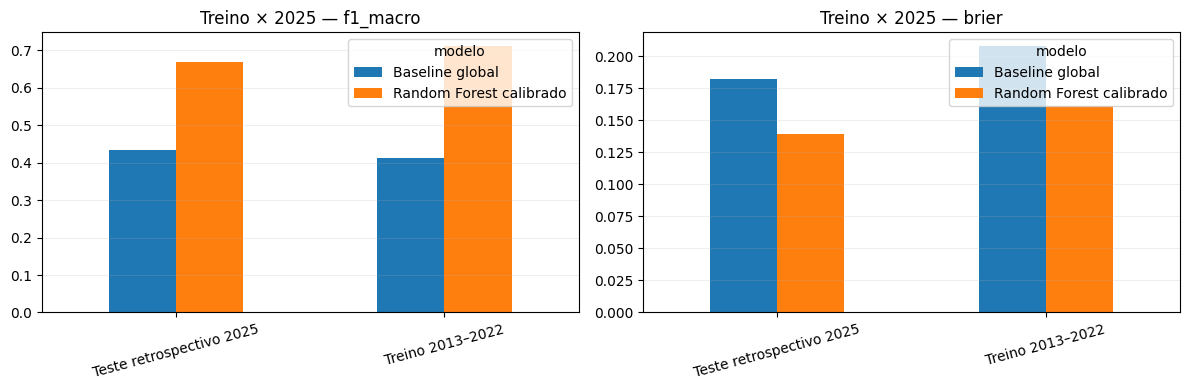

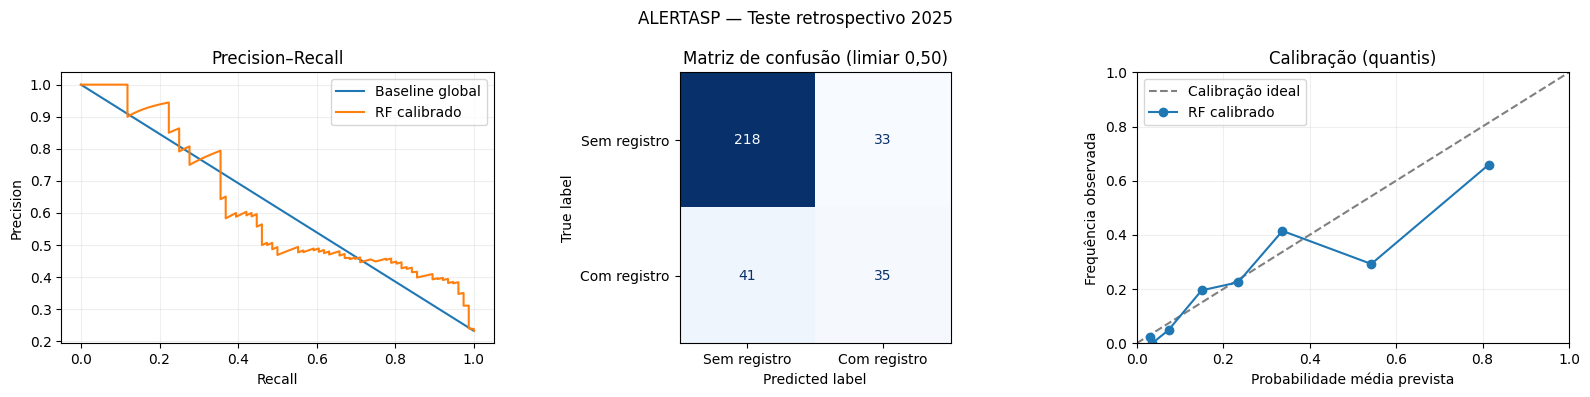

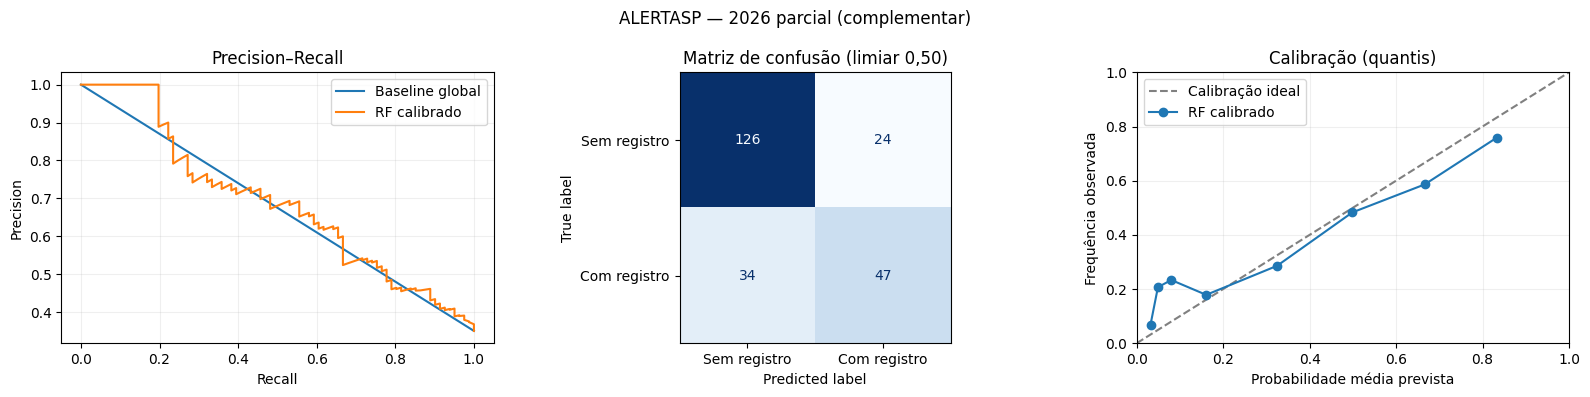

In [34]:
# Gráfico comparativo principal em treino e 2025.
comparar=avaliacoes.loc[(avaliacoes.modelo.isin(["Baseline global","Random Forest calibrado"])) &
    (avaliacoes.conjunto.isin(["Treino 2013–2022","Teste retrospectivo 2025"]))]
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metr in zip(axes,["f1_macro","brier"]):
    pivot=comparar.pivot(index="conjunto",columns="modelo",values=metr)
    pivot.plot(kind="bar",ax=ax,rot=15)
    ax.set_title(f"Treino × 2025 — {metr}");ax.set_xlabel("")
    ax.grid(axis="y",alpha=.2)
plt.tight_layout();plt.savefig(FIGURAS/"treino_vs_teste_2025.png",dpi=150,bbox_inches="tight");plt.show()

for nome in ["Teste retrospectivo 2025"] + (["2026 parcial (complementar)"] if len(TEST26) else []):
    d=probabilidades[nome]
    fig,axs=plt.subplots(1,3,figsize=(16,4))
    # AUC-PR
    for chave,label in [("base","Baseline global"),("calibrado","RF calibrado")]:
        pr,re,th=precision_recall_curve(d["y"],d[chave])
        axs[0].plot(re,pr,label=label)
    axs[0].set(xlabel="Recall",ylabel="Precision",title="Precision–Recall")
    axs[0].legend();axs[0].grid(alpha=.2)
    # Confusão
    cm=confusion_matrix(d["y"],(d["calibrado"]>=.5).astype(int),labels=[0,1])
    ConfusionMatrixDisplay(cm,display_labels=["Sem registro","Com registro"]).plot(ax=axs[1],colorbar=False,cmap="Blues")
    axs[1].set_title("Matriz de confusão (limiar 0,50)")
    # Confiabilidade (faixas por quantis)
    predm,observ=calibration_curve(d["y"],d["calibrado"],n_bins=8,strategy="quantile")
    axs[2].plot([0,1],[0,1],"--",color="gray",label="Calibração ideal")
    axs[2].plot(observ,predm,"o-",label="RF calibrado")
    axs[2].set(xlabel="Probabilidade média prevista",ylabel="Frequência observada",xlim=(0,1),ylim=(0,1),title="Calibração (quantis)")
    axs[2].legend();axs[2].grid(alpha=.2)
    plt.suptitle(f"ALERTASP — {nome}");plt.tight_layout()
    arq="teste_2025" if "2025" in nome else "avaliacao_2026"
    plt.savefig(FIGURAS/f"{arq}_graficos.png",dpi=150,bbox_inches="tight");plt.show()

## 11. Associação descritiva: chuva anterior × frequência de registros
A tabela abaixo é **observacional**, não um limiar oficial de alerta. As faixas são apenas categorias exploratórias (0, 0–5, 5–20, 20–50, >50 mm no dia anterior). Dias com chuva forte no mesmo dia podem não ser antecipados pela precipitação anterior. Os resultados são específicos da estação A701 e **não** devem ser transferidos para uma rua.

,faixa_chuva_d1,dias,dias_com_registro,taxa_observada,taxa_observada_%
0,0 mm,2741,498,0.181686,18.17
1,>0 a 5 mm,1110,372,0.335135,33.51
2,>5 a 20 mm,584,314,0.537671,53.77
3,>20 a 50 mm,282,189,0.670213,67.02
4,>50 mm,48,42,0.875000,87.50


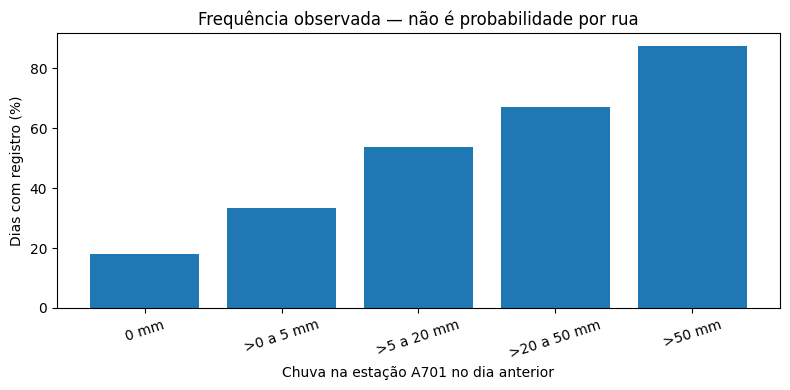

In [35]:
faixas=[-0.00001,0,5,20,50,np.inf]
labels=["0 mm",">0 a 5 mm",">5 a 20 mm",">20 a 50 mm",">50 mm"]
aux=modelagem.copy()
aux["faixa_chuva_d1"] = pd.cut(aux.chuva_d1_mm,bins=faixas,labels=labels,include_lowest=True)
tabela_chuva=aux.groupby("faixa_chuva_d1",observed=False).houve_registro.agg(
    dias="size", dias_com_registro="sum", taxa_observada="mean").reset_index()
tabela_chuva["taxa_observada_%"]=(100*tabela_chuva.taxa_observada).round(2)
display(tabela_chuva)
tabela_chuva.to_csv(EVIDENCIAS/"associacao_chuva_anterior_registros.csv",index=False)
fig,ax=plt.subplots(figsize=(8,4))
ax.bar(tabela_chuva.faixa_chuva_d1.astype(str),tabela_chuva["taxa_observada_%"])
ax.set(ylabel="Dias com registro (%)",xlabel="Chuva na estação A701 no dia anterior",title="Frequência observada — não é probabilidade por rua")
plt.xticks(rotation=18);plt.tight_layout();plt.savefig(FIGURAS/"faixas_chuva_frequencia.png",dpi=150);plt.show()

## 12. Diagnóstico de sobreajuste, interpretação e prudência
- Compare treino e 2025 em F1-macro e Brier. Desempenho maior em treino pode significar sobreajuste.
- Teste se o modelo supera baselines de frequência **em Average Precision e Brier** no teste. Não confunda accuracy alta com boa previsão de registros.
- A calibração foi ajustada exclusivamente em 2023; o treino não mede generalização.
- A estação A701 representa uma medição pontual. Chuvas convectivas podem ser localizadas; falta radar pluviométrico, rede de pluviômetros e horário das ocorrências.
- O SIGRC tem subnotificação, diferenças de cobertura e atualização mensal/ETL sem sincronismo. Ausência de registro não é ausência de fenômeno.
- 2026 é parcial e a data da dados de 2026 são analisados somente até 30/09, com referência ao metadado revisado em 06/10; publicação mensal não garante completude nem ausência de atraso.
- Não converter porcentagens do notebook em avisos oficiais nem recomendar trajetos seguros. O protótipo é pesquisa histórica.

In [36]:
# Leitura automática dos resultados: evita inventar números no relatório.
sel=avaliacoes.set_index(["conjunto","modelo"])
key="Teste retrospectivo 2025"
rf25=sel.loc[(key,"Random Forest calibrado")]
b0=sel.loc[(key,"Baseline global")]
bm=sel.loc[(key,"Baseline mensal")]
melhora=(rf25.brier < b0.brier) and (rf25.brier < bm.brier) and (rf25.average_precision > bm.average_precision)
print("Diagnóstico de qualidade probabilística:")
print("RF calibrado versus baseline global, Brier:",round(rf25.brier,4),round(b0.brier,4))
print("RF calibrado versus baseline mensal, Brier:",round(rf25.brier,4),round(bm.brier,4))
print("RF calibrado versus baseline mensal, Average Precision:",round(rf25.average_precision,4),round(bm.average_precision,4))
if melhora:
    print("Sinal favorável em 2025; ainda NÃO é validação operacional de risco por rua.")
else:
    print("ATENÇÃO: o RF não superou todos os baselines no critério pré-definido. Não exibir percentual ao cidadão como estimativa confiável.")

Diagnóstico de qualidade probabilística:
RF calibrado versus baseline global, Brier: 0.1395 0.1824
RF calibrado versus baseline mensal, Brier: 0.1395 0.1387
RF calibrado versus baseline mensal, Average Precision: 0.6233 0.5682
ATENÇÃO: o RF não superou todos os baselines no critério pré-definido. Não exibir percentual ao cidadão como estimativa confiável.


## 13. Demonstração do produto: probabilidade retrospectiva para dias reais

Para responder à pergunta de produto com **dados observados**, apresentamos cinco datas de 2025 com maior chuva **no dia anterior** à ocorrência e a porcentagem prevista pelo modelo. A amostra é ilustrativa, não serve para medir qualidade estatística (as métricas estão nos outros conjuntos). A estimativa é **municipal, retrospectiva e condicionada a toda a janela de chuva, não somente a milímetros do dia anterior**. Não é alerta para hoje nem previsão por bairro ou rua.

In [37]:
exemplos = TEST25.copy()
exemplos["prob_registro_pct"] = np.round(100*prever_probabilidade(exemplos)[1],2)
exemplos = exemplos.sort_values(["chuva_d1_mm","dia"],ascending=[False,True]).head(5)
print("EXEMPLOS HISTÓRICOS REAIS — 2025 (não é previsão em tempo real):")
display(exemplos[["dia", "chuva_d1_mm", "chuva_d3_mm", "chuva_d7_mm",
                 "horas_chuvosas_d1", "prob_registro_pct", "houve_registro"]])
exemplos[["dia", "chuva_d1_mm", "chuva_d3_mm", "chuva_d7_mm",
          "prob_registro_pct", "houve_registro"]].to_csv(
             EVIDENCIAS/"exemplos_reais_2025_probabilidades.csv",index=False)
print("Uma porcentagem é estimativa de REGISTRO MUNICIPAL no dia-alvo, nunca probabilidade de alagamento de uma rua.")

EXEMPLOS HISTÓRICOS REAIS — 2025 (não é previsão em tempo real):


,dia,chuva_d1_mm,chuva_d3_mm,chuva_d7_mm,horas_chuvosas_d1,prob_registro_pct,houve_registro
23,2025-01-25,125.6,139.0,144.0,5.0,95.33,1
31,2025-02-02,63.6,94.6,184.6,15.0,95.56,1
308,2025-12-10,59.4,59.4,62.4,19.0,80.31,1
89,2025-04-15,55.6,60.6,85.2,4.0,83.03,1
259,2025-10-19,45.8,47.6,48.2,15.0,76.38,0


Uma porcentagem é estimativa de REGISTRO MUNICIPAL no dia-alvo, nunca probabilidade de alagamento de uma rua.


## 14. Registro de evidências, versões e reprodutibilidade

In [38]:

# 14. REGISTRO FINAL DE EVIDENCIAS E REPRODUTIBILIDADE

from datetime import datetime, timezone
from importlib.metadata import version as package_version
import hashlib
import json
import joblib
import pandas as pd

def sha256(path):
    h = hashlib.sha256()

    with open(path, "rb") as arquivo:
        for bloco in iter(
            lambda: arquivo.read(1024 * 1024),
            b""
        ):
            h.update(bloco)

    return h.hexdigest()

# Registrar as versoes reais do ambiente.
pacotes = [
    "numpy",
    "pandas",
    "scikit-learn",
    "matplotlib",
    "joblib"
]

requirements = "\n".join(
    f"{pacote}=={package_version(pacote)}"
    for pacote in pacotes
) + "\n"

(BASE / "requirements.txt").write_text(
    requirements,
    encoding="utf-8"
)

versoes = {
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "sklearn": sklearn.__version__,
    "matplotlib": plt.matplotlib.__version__,
    "joblib": joblib.__version__,
    "gerado_utc": datetime.now(timezone.utc).isoformat()
}

(EVIDENCIAS / "versoes_execucao.json").write_text(
    json.dumps(versoes, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

# Preservar a rastreabilidade dos dados oficiais.
manifesto = [{
    "arquivo": str(ZIP_GEO.relative_to(BRUTOS)),
    "sha256": sha256(ZIP_GEO),
    "origem": "GeoSampa"
}]

for arquivo in csvs_a701:
    manifesto.append({
        "arquivo": str(arquivo.relative_to(BRUTOS)),
        "sha256": sha256(arquivo),
        "origem": "INMET A701"
    })

pd.DataFrame(manifesto).to_csv(
    EVIDENCIAS / "manifesto_sha256.csv",
    index=False
)

# Registrar o protocolo do modelo selecionado.
modelo_info = {
    "modelo": "RandomForestClassifier",
    "parametros": busca.best_params_,
    "features": FEATURES,
    "anos_desenvolvimento": "2013-2022",
    "ano_calibracao": 2023,
    "ano_verificacao": 2024,
    "ano_teste": 2025,
    "2026_parcial": bool(len(TEST26)),
    "limiar_classificacao": 0.5,
    "alvo": "ao menos um registro SIGRC na cidade no dia"
}

(EVIDENCIAS / "protocolo_modelo.json").write_text(
    json.dumps(modelo_info, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

# Salvar o modelo experimental.
joblib.dump(
    {
        "rf": modelo_rf,
        "calibrador": calibrador,
        "features": FEATURES,
        "protocolo": modelo_info
    },
    EVIDENCIAS / "modelo_experimental.joblib"
)

print("Evidencias registradas com sucesso!")
print("Requirements e versoes atualizados.")
print("Manifesto SHA-256 gerado.")
print("Modelo experimental salvo.")
print("O relatorio definitivo nao foi modificado.")


Evidencias registradas com sucesso!
Requirements e versoes atualizados.
Manifesto SHA-256 gerado.
Modelo experimental salvo.
O relatorio definitivo nao foi modificado.


## 15. Revisão final como avaliador da FIAP
**Antes de publicar no GitHub:**

1. Confirmar que 2013–2025 A701 estão presentes e que a estação aparece nos metadados (2026 opcional como análise parcial).
2. Mostrar no notebook executado o inventário, o painel, a divisão, as 12 combinações × 3 parâmetros, os quatro folds cronológicos, os baselines, métricas treino/teste, gráficos, calibração, matriz de confusão e interpretação de erros.
3. Conferir a extensão do relatório e o `dados/README.md` com fontes, links, datas, unidades, período, cobertura, limitações e condições de uso.
4. Se a calibração/Brier/AP não forem satisfatórios, **não exibir porcentagem como probabilidade operacional**: apresentar somente os resultados históricos do experimento e limitações.
5. Registrar os prompts verdadeiros em `prompts.md`. Não afirmar que a IA foi validada para alertar cidadãos.
6. Publicar notebook com saídas no GitHub e vídeo não listado de até 5 min. Enviar **links do GitHub e YouTube** no Teams até 19/11/2026 23h55.

**Atenção:** se houver resultados modestos, isso não invalida o experimento acadêmico. A rubrica exige rigor, não uma porcentagem mínima de accuracy.

## 16. Conclusão crítica e implicações para o cidadão

O ALERTASP investigou se a precipitação observada anteriormente na estação INMET A701 (São Paulo–Mirante) permite estimar a possibilidade de haver pelo menos um registro administrativo de alagamento ou inundação na cidade de São Paulo durante as próximas 24 horas.

Foram utilizados dados reais e públicos do INMET e do GeoSampa, referentes a 2013–2026. O modelo Random Forest foi treinado com 3.585 dias elegíveis de 2013–2022, utilizando quatro folds cronológicos e 12 combinações de três hiperparâmetros. A melhor configuração apresentou 300 árvores, profundidade máxima de 4 e mínimo de 20 observações por folha, com Average Precision média de **0,6141** na validação cruzada.

No teste retrospectivo de 2025, com 327 dias elegíveis, o modelo calibrado obteve **Average Precision de 0,6233, Brier Score de 0,1395 e F1-macro de 0,6705**. O baseline mensal apresentou Average Precision de 0,5682, Brier Score de 0,1387 e F1-macro de 0,7312.

Portanto, o Random Forest apresentou maior capacidade de ordenar os dias conforme a possibilidade de registro, mas não demonstrou probabilidades mais precisas do que a referência sazonal segundo o Brier Score.

A matriz de confusão de 2025 revelou 218 verdadeiros negativos, 35 verdadeiros positivos, 33 falsos positivos e 41 falsos negativos. O número de falsos negativos merece atenção, pois representa dias com registros que o classificador não identificou no limiar adotado.

Na avaliação complementar de 2026, com 231 dias elegíveis, o modelo calibrado obteve Average Precision de **0,6912**, Brier Score de **0,1829** e F1-macro de **0,7157**. Esse resultado não comprova melhora do algoritmo, pois os períodos apresentam condições e distribuições distintas.

A análise histórica também identificou associação entre maiores acumulados de precipitação no dia anterior e maior frequência de registros municipais. Essa associação não estabelece causalidade nem permite definir limites operacionais de alerta.

As principais limitações incluem possíveis subnotificações e atrasos nos registros da Defesa Civil, falhas meteorológicas, cobertura espacial limitada à estação A701 e ausência de informações sobre ocorrências físicas não registradas.

**Concluímos que a pergunta de Machine Learning foi investigada com sucesso, mas as porcentagens produzidas ainda não possuem confiabilidade demonstrada para uso operacional pelo cidadão.** O modelo não prevê alagamentos por rua, não determina rotas seguras e não substitui as informações oficiais do CGE e da Defesa Civil.

O principal resultado do ALERTASP nesta disciplina é demonstrar, com dados reais e metodologia reproduzível, a relação observacional entre chuva anterior e registros históricos, oferecendo conhecimento exploratório relevante aos ODS 11 e 13, com o ODS 3 como complementar.